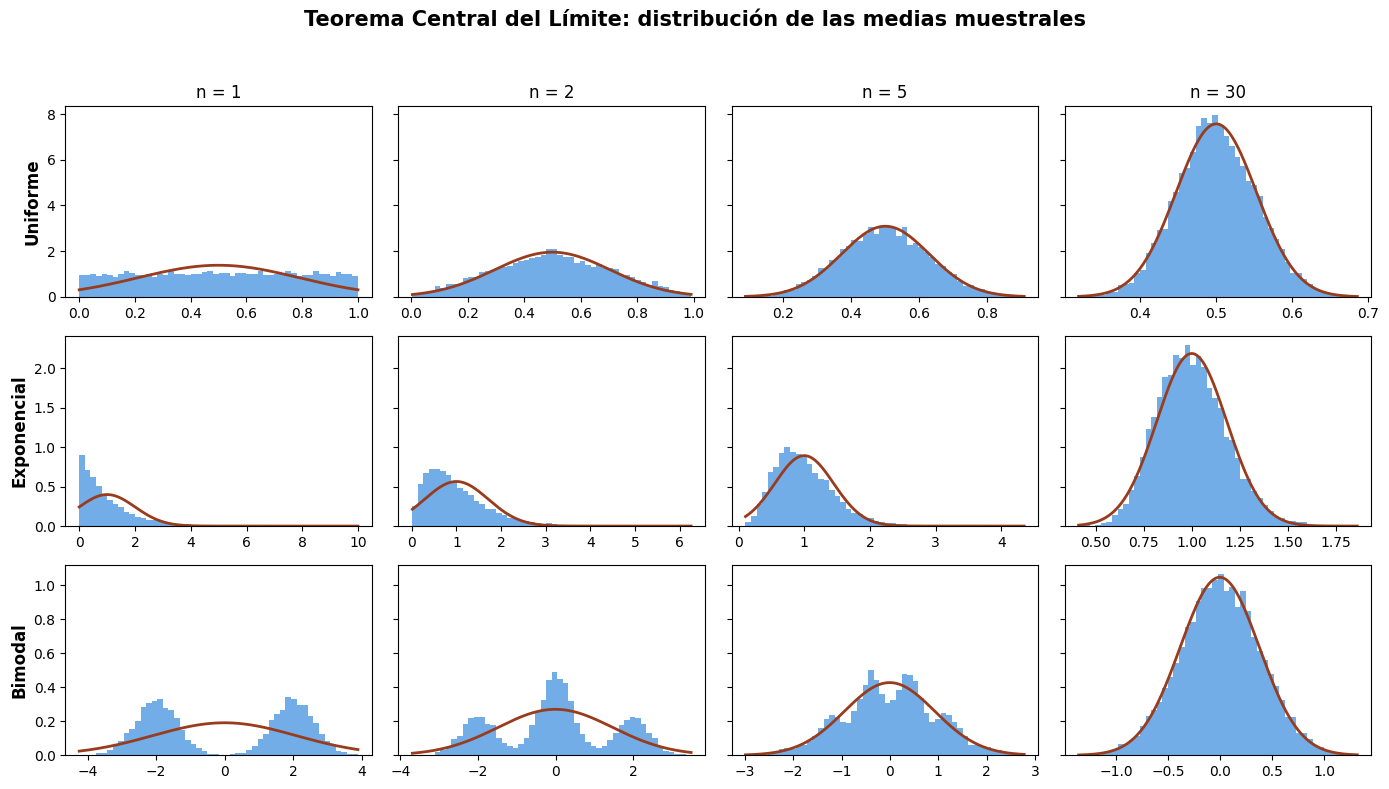


Asimetría de las medias (0 = simétrica, como una normal):
Población     n=1       n=2       n=5       n=30      
Uniforme      0.024     0.022     0.011     0.016     
Exponencial   1.988     1.409     0.939     0.383     
Bimodal       0.023     -0.018    -0.007    -0.006    


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

def uniforme(tam):
    return rng.uniform(0, 1, tam)

def exponencial(tam):
    return rng.exponential(scale=1.0, size=tam)

def bimodal(tam):
    mezcla = rng.integers(0, 2, tam)
    return np.where(mezcla == 0, rng.normal(-2, 0.6, tam), rng.normal(2, 0.6, tam))

poblaciones = {
    "Uniforme": uniforme,
    "Exponencial": exponencial,
    "Bimodal": bimodal,
}

tamanos_n = [1, 2, 5, 30]
num_muestras = 10_000

fig, ejes = plt.subplots(
    len(poblaciones), len(tamanos_n), figsize=(14, 8), sharey="row"
)
fig.suptitle("Teorema Central del Límite: distribución de las medias muestrales",
             fontsize=15, fontweight="bold")

for i, (nombre, generador) in enumerate(poblaciones.items()):

    datos_pob = generador(1_000_000)
    mu, sigma = datos_pob.mean(), datos_pob.std()

    for j, n in enumerate(tamanos_n):
        medias = generador((num_muestras, n)).mean(axis=1)

        ax = ejes[i, j]
        ax.hist(medias, bins=50, density=True, color="#378ADD", alpha=0.7)

        x = np.linspace(medias.min(), medias.max(), 300)
        ax.plot(x, stats.norm.pdf(x, mu, sigma / np.sqrt(n)),
                color="#993C1D", linewidth=2)

        if i == 0:
            ax.set_title(f"n = {n}")
        if j == 0:
            ax.set_ylabel(nombre, fontsize=12, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("teorema_central_limite.png", dpi=150)
plt.show()

print("\nAsimetría de las medias (0 = simétrica, como una normal):")
print(f"{'Población':<14}" + "".join(f"n={n:<8}" for n in tamanos_n))
for nombre, generador in poblaciones.items():
    fila = f"{nombre:<14}"
    for n in tamanos_n:
        medias = generador((num_muestras, n)).mean(axis=1)
        fila += f"{stats.skew(medias):<10.3f}"
    print(fila)